Training plain neural network (data only)...
  epoch     0  loss 0.61974
  epoch  2000  loss 0.00031
  epoch  4000  loss 0.00028
  epoch  6000  loss 0.00039
Training PINN (data + physics)...
  epoch     0  loss 0.74289
  epoch  2000  loss 0.00520
  epoch  4000  loss 0.00192
  epoch  6000  loss 0.00262

Prediction error in the future (t > 2.0s):
  Plain NN : 1.9623 rad RMSE
  PINN     : 0.0085 rad RMSE


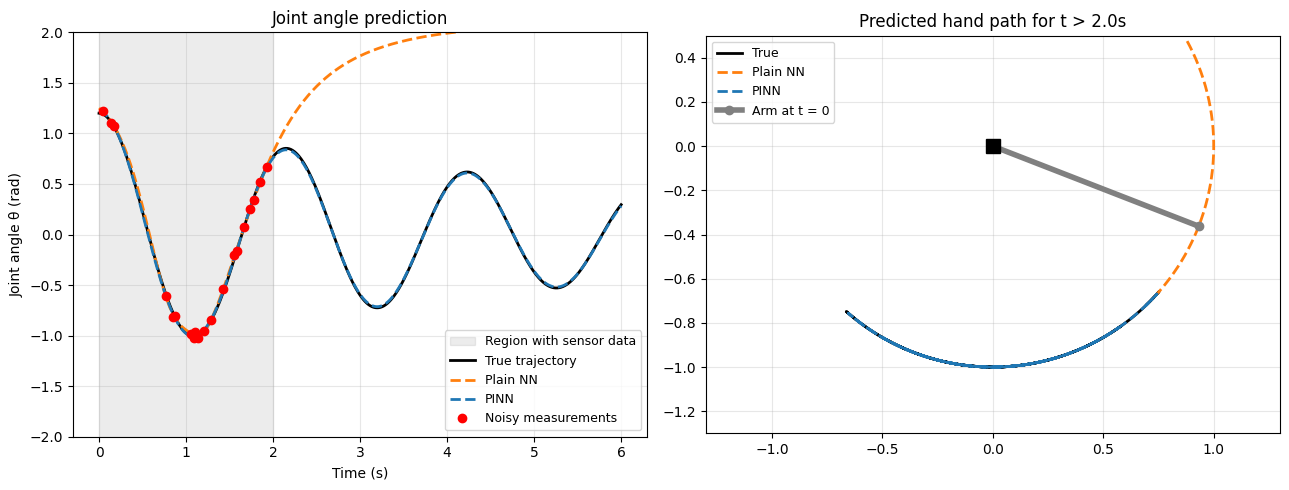

In [1]:
"""
PINN-based Robot Trajectory Prediction
A single robot joint (one-link arm) swings under gravity with friction.
We only measure its angle for the first 2 seconds (noisy sensor), and
want to predict the trajectory up to 6 seconds.

  - Plain neural network: learns from data only -> fails outside the data.
  - PINN: learns from data + the physics equation -> predicts the future.

Physics (equation of motion of the arm):
    theta'' + b * theta' + (g / L) * sin(theta) = 0

Runs on Colab: torch, numpy, scipy, matplotlib are all preinstalled.
"""
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

torch.manual_seed(0)
np.random.seed(0)

# ---------------- Robot arm physics ----------------
g, L, b = 9.81, 1.0, 0.3        # gravity, link length, joint friction
theta0, omega0 = 1.2, 0.0       # start: arm raised to 1.2 rad, at rest
T_DATA, T_END = 2.0, 6.0        # we have sensor data only up to T_DATA

def arm_dynamics(t, y):
    theta, omega = y
    return [omega, -b * omega - (g / L) * np.sin(theta)]

# "True" trajectory from a numerical solver (used only for checking)
t_true = np.linspace(0, T_END, 600)
sol = solve_ivp(arm_dynamics, [0, T_END], [theta0, omega0], t_eval=t_true, rtol=1e-9)
theta_true = sol.y[0]

# Noisy sensor measurements: 20 points in the first 2 seconds
t_data = np.sort(np.random.uniform(0, T_DATA, 20))
theta_data = np.interp(t_data, t_true, theta_true) + 0.02 * np.random.randn(20)

t_data_tensor = torch.tensor(t_data, dtype=torch.float32).view(-1, 1)
theta_data_tensor = torch.tensor(theta_data, dtype=torch.float32).view(-1, 1)

# Collocation points: where we enforce the physics (whole time range)
t_phys = torch.linspace(0, T_END, 300).view(-1, 1).requires_grad_(True)

# ---------------- Neural network: t -> theta(t) ----------------
def make_net():
    return nn.Sequential(
        nn.Linear(1, 64), nn.Tanh(),
        nn.Linear(64, 64), nn.Tanh(),
        nn.Linear(64, 64), nn.Tanh(),
        nn.Linear(64, 1),
    )

def physics_residual(net, t):
    theta = net(t)
    dtheta = torch.autograd.grad(theta, t, torch.ones_like(theta), create_graph=True)[0]
    d2theta = torch.autograd.grad(dtheta, t, torch.ones_like(dtheta), create_graph=True)[0]
    return d2theta + b * dtheta + (g / L) * torch.sin(theta)

def train(use_physics, epochs=8000):
    net = make_net()
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    for ep in range(epochs):
        opt.zero_grad()
        loss = torch.mean((net(t_data_tensor) - theta_data_tensor) ** 2)   # data loss
        if use_physics:
            loss_phys = torch.mean(physics_residual(net, t_phys) ** 2)
            loss = loss + 0.01 * loss_phys                                # physics loss
        loss.backward()
        opt.step()
        if ep % 2000 == 0:
            print(f"  epoch {ep:5d}  loss {loss.item():.5f}")
    return net

print("Training plain neural network (data only)...")
nn_model = train(use_physics=False)
print("Training PINN (data + physics)...")
pinn_model = train(use_physics=True)

# ---------------- Evaluate ----------------
t_test = torch.tensor(t_true, dtype=torch.float32).view(-1, 1)
with torch.no_grad():
    theta_nn = nn_model(t_test).numpy().flatten()
    theta_pinn = pinn_model(t_test).numpy().flatten()

future = t_true > T_DATA
print(f"\nPrediction error in the future (t > {T_DATA}s):")
print(f"  Plain NN : {np.sqrt(np.mean((theta_nn[future] - theta_true[future]) ** 2)):.4f} rad RMSE")
print(f"  PINN     : {np.sqrt(np.mean((theta_pinn[future] - theta_true[future]) ** 2)):.4f} rad RMSE")

# ---------------- Plots ----------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.axvspan(0, T_DATA, color="gray", alpha=0.15, label="Region with sensor data")
ax1.plot(t_true, theta_true, "k-", lw=2, label="True trajectory")
ax1.plot(t_true, theta_nn, "--", color="tab:orange", lw=2, label="Plain NN")
ax1.plot(t_true, theta_pinn, "--", color="tab:blue", lw=2, label="PINN")
ax1.plot(t_data, theta_data, "ro", label="Noisy measurements")
ax1.set_xlabel("Time (s)"); ax1.set_ylabel("Joint angle θ (rad)")
ax1.set_ylim(-2, 2); ax1.grid(alpha=0.3); ax1.legend(loc="lower right", fontsize=9)
ax1.set_title("Joint angle prediction")

# Hand (end-effector) position: angle measured from straight down
def hand(theta):
    return L * np.sin(theta), -L * np.cos(theta)

for theta, ls, color, label in [(theta_true, "-", "k", "True"),
                                (theta_nn, "--", "tab:orange", "Plain NN"),
                                (theta_pinn, "--", "tab:blue", "PINN")]:
    x, y = hand(theta[future])
    ax2.plot(x, y, linestyle=ls, color=color, lw=2, label=label)
x0, y0 = hand(theta0)
ax2.plot([0, x0], [0, y0], "-o", color="gray", lw=4, label="Arm at t = 0")
ax2.plot(0, 0, "ks", markersize=10)
ax2.set_xlim(-1.3, 1.3); ax2.set_ylim(-1.3, 0.5)
ax2.set_aspect("equal"); ax2.grid(alpha=0.3); ax2.legend(fontsize=9)
ax2.set_title(f"Predicted hand path for t > {T_DATA}s")

plt.tight_layout()
plt.savefig("pinn_result.png", dpi=120)
plt.show()
